# Part 4: Gradient Descent in Code
We convert the manual Part 3 calculations into Python, with the same data, starting values and learning rate, so the first three iterations match the handwritten PDF.

**Model (matrix form):** $\hat{y} = Xm + b$, **cost:** $J = \frac{1}{n} e^T e$ with $e = \hat{y} - y$

**Chain rule:** $\frac{\partial J}{\partial m} = \frac{2}{n} X^T e$, $\frac{\partial J}{\partial b} = \frac{2}{n} e$

In [1]:
import numpy as np
import gradient_descent as gd

print("X =\n", gd.X)
print("y =", gd.Y, "| m =", gd.M_START, "| b =", gd.B_START, "| alpha =", gd.ALPHA)

X =
 [[ 1.  3.]
 [ 4. 10.]]
y = [5. 6.] | m = [-1.  2.] | b = [1. 1.] | alpha = 0.01


## 1. Why b is a vector
The brief gives **b = [1, 1]**, two values. We treat it as **one bias per data point**: b1 is added to the first prediction and b2 to the second. So each b only affects its own row:

$$\frac{\partial J}{\partial b_i} = \frac{2}{n} e_i$$

That gives four parameters to learn: m1, m2, b1, b2. (If b were one shared number, its gradient would be the sum $\frac{2}{n}\sum e_i$ instead.)

## 2. SciPy derivative function
`gd.derivative` accepts any equation and returns its derivative using SciPy. Quick test on $f(x) = x^2 + 3x$, where $f'(2) = 2(2) + 3 = 7$:

In [2]:
print(gd.derivative(lambda p: p[0]**2 + 3*p[0], [2.0]))

[7.000001]


## 3. Checking all four derivatives
Our chain-rule formulas must match SciPy's numerical derivatives for m1, m2, b1 and b2:

In [3]:
print("All match:", gd.check_derivatives(gd.X, gd.Y, gd.M_START, gd.B_START))

param   chain rule       SciPy  match
m1         45.0000     45.0000  yes
m2        113.0000    113.0001  yes
b1          1.0000      1.0000  yes
b2         11.0000     11.0000  yes
All match: True


## 4. Gradient descent: three iterations (one per group member)
Every calculation step is printed, so it can be compared line by line with the handwritten Part 3.

In [4]:
m3, b3, _ = gd.run_gradient_descent(gd.X, gd.Y, gd.M_START, gd.B_START, gd.ALPHA, iterations=3)
print("After 3 iterations: m =", np.round(m3, 4), " b =", np.round(b3, 4))

--- Iteration 1 ---
y_hat = X m + b       = [ 6. 17.]
error = y_hat - y     = [ 1. 11.]
J (MSE)               = 61.0000
dJ/dm = (2/n) X^T e   = [ 45. 113.]
dJ/db = (2/n) e       = [ 1. 11.]
m_new = m - a*dJ/dm   = [-1.45  0.87]
b_new = b - a*dJ/db   = [0.99 0.89]

--- Iteration 2 ---
y_hat = X m + b       = [2.15 3.79]
error = y_hat - y     = [-2.85 -2.21]
J (MSE)               = 6.5033
dJ/dm = (2/n) X^T e   = [-11.69 -30.65]
dJ/db = (2/n) e       = [-2.85 -2.21]
m_new = m - a*dJ/dm   = [-1.3331  1.1765]
b_new = b - a*dJ/db   = [1.0185 0.9121]

--- Iteration 3 ---
y_hat = X m + b       = [3.2149 7.3447]
error = y_hat - y     = [-1.7851  1.3447]
J (MSE)               = 2.4974
dJ/dm = (2/n) X^T e   = [3.5937 8.0917]
dJ/db = (2/n) e       = [-1.7851  1.3447]
m_new = m - a*dJ/dm   = [-1.369   1.0956]
b_new = b - a*dJ/db   = [1.0364 0.8987]

After 3 iterations: m = [-1.369   1.0956]  b = [1.0364 0.8987]


## 5. Running longer
We continue to 50 iterations to see where the parameters settle, printing nothing except the final values.

In [5]:
m_final, b_final, history = gd.run_gradient_descent(gd.X, gd.Y, gd.M_START, gd.B_START, gd.ALPHA, iterations=50, show_first=0)
print("Final m =", np.round(m_final, 4), " Final b =", np.round(b_final, 4))
print("Final MSE =", round(history["cost"][-1], 6))

Final m = [-1.4904  1.1637]  Final b = [1.7795 0.6825]
Final MSE = 0.808003


## 6. Predictions with the final m and b

In [6]:
y_hat = gd.predict(gd.X, m_final, b_final)
for i in range(len(gd.Y)):
    print(f"Point {i + 1}: x = {gd.X[i]}  true y = {gd.Y[i]}  predicted y = {y_hat[i]:.4f}")

Point 1: x = [1. 3.]  true y = 5.0  predicted y = 3.7801
Point 2: x = [ 4. 10.]  true y = 6.0  predicted y = 6.3576


## 7. Plots

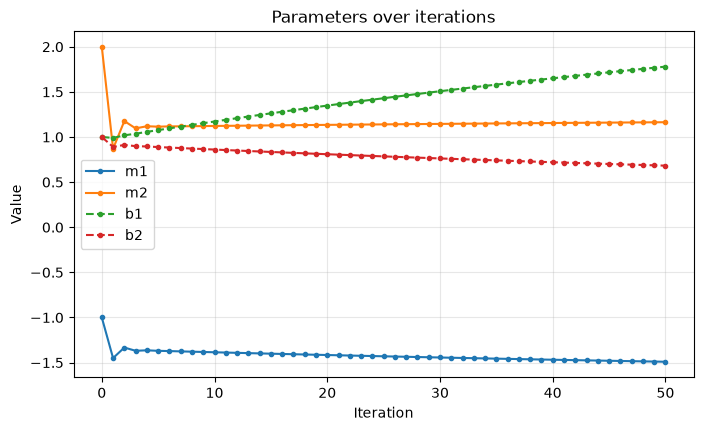

In [7]:
gd.plot_parameters(history, save_path="parameters.png")

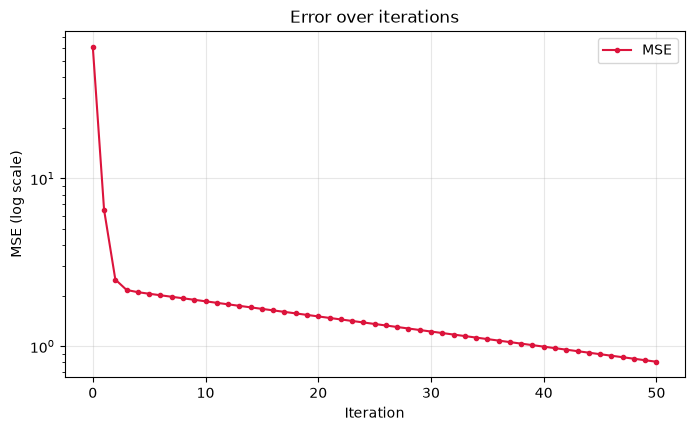

In [8]:
gd.plot_error(history, save_path="error.png")

## 8. Trend
The error falls every iteration: 61 → 6.50 → 2.50 → 2.16 over the first three, then keeps shrinking. So yes, m and b move in a direction that reduces the error. The first step is the biggest because the starting error is large; later steps get smaller as the gradients shrink. Some gradients change sign around iteration 3, showing a small overshoot that gradient descent then corrects.